# Student Placement & Salary Prediction: 

---
# Part 1: Data Understanding

## 1. Libraries import 

In [53]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)  

In [2]:
DATA_PATH = '../datasets/studentplacement.csv'
raw = pd.read_csv(DATA_PATH)
print('Rows, Columns =', raw.shape)

Rows, Columns = (100000, 26)


In [3]:
raw.head()

,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,81.707722,57.707166,59.070073,4,1,184,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,63.116715,59.197085,78.976419,0,2,539,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,48.658753,92.104885,80.603331,0,2,568,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,66.376653,83.411798,64.187246,1,1,550,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,61.274985,88.956331,56.163678,1,4,833,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


In [4]:
pd.DataFrame({'dtype': raw.dtypes.astype(str), 'non_null': raw.notnull().sum(), 'unique_values': raw.nunique()})

,dtype,non_null,unique_values
student_id,int64,100000,100000
age,int64,100000,7
gender,object,100000,2
cgpa,float64,100000,551
branch,object,100000,6
college_tier,object,100000,3
internships_count,int64,100000,9
projects_count,int64,100000,14
certifications_count,int64,100000,12
coding_skill_score,float64,100000,97643


## 5. Numerical columns statistical summary

In [5]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
student_id,100000.0,50000.50,28867.66,1.0,25000.75,50000.50,75000.25,100000.00
age,100000.0,21.01,2.00,18.0,19.00,21.00,23.00,24.00
cgpa,100000.0,7.50,0.99,4.5,6.82,7.50,8.18,10.00
internships_count,100000.0,1.50,1.23,0.0,1.00,1.00,2.00,8.00
projects_count,100000.0,3.00,1.73,0.0,2.00,3.00,4.00,13.00
certifications_count,100000.0,2.01,1.42,0.0,1.00,2.00,3.00,11.00
coding_skill_score,100000.0,69.83,14.69,20.0,59.81,70.01,80.06,100.00
aptitude_score,100000.0,64.99,14.84,20.0,54.89,65.01,75.08,100.00
communication_skill_score,100000.0,67.96,13.85,20.0,58.59,67.97,77.50,100.00
logical_reasoning_score,100000.0,65.93,14.83,20.0,55.94,66.00,76.11,100.00


## 6. Categorical columns values

In [6]:
cat_cols = raw.select_dtypes(include=['object', 'string']).columns.tolist()
print('Categorical columns:', cat_cols)
for c in cat_cols:
    print('\n' + c)
    print(raw[c].value_counts().to_string())

Categorical columns: ['gender', 'branch', 'college_tier', 'volunteer_experience', 'placement_status']

gender
gender
Male      60028
Female    39972

branch
branch
CSE           34818
IT            19999
ECE           14908
EEE           10177
Mechanical    10077
Civil         10021

college_tier
college_tier
Tier 2    49955
Tier 3    29884
Tier 1    20161

volunteer_experience
volunteer_experience
No     59963
Yes    40037

placement_status
placement_status
Placed        54459
Not Placed    45541


## 7. Missing values aur duplicate rows
Data quality check: kya koi column khali hai ya koi row repeat hui hai?

In [7]:
print('Total missing values :', int(raw.isnull().sum().sum()))
print('Duplicate rows         :', int(raw.duplicated().sum()))
print('Duplicate student_id    :', int(raw['student_id'].duplicated().sum()))

Total missing values : 0
Duplicate rows         : 0
Duplicate student_id    : 0


## 8. Target variables

In [8]:
print(raw['placement_status'].value_counts().to_string())
print('\nPlacement rate: {:.2f}%'.format((raw['placement_status'] == 'Placed').mean() * 100))
raw.groupby('placement_status')['salary_package_lpa'].describe().round(2)

placement_status
Placed        54459
Not Placed    45541

Placement rate: 54.46%


,count,mean,std,min,25%,50%,75%,max
placement_status,,,,,,,,
Not Placed,45541.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00
Placed,54459.0,13.32,1.59,7.11,12.23,13.3,14.39,20.44


---
# Part 2: Exploratory Data Analysis (EDA)

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raw = pd.read_csv('../datasets/studentplacement.csv')
placed = raw[raw['placement_status'] == 'Placed'].copy()
print('All students:', len(raw), '| Placed students:', len(placed))

All students: 100000 | Placed students: 54459


## 2. Placed vs Not Placed

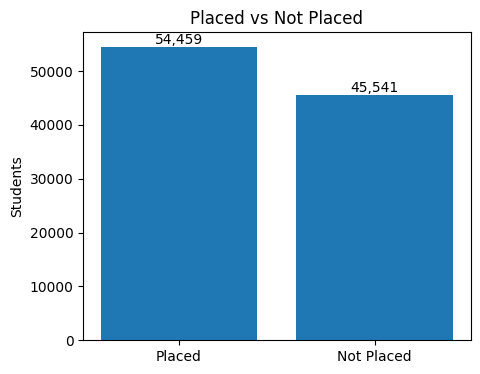

In [10]:
counts = raw['placement_status'].value_counts()
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(counts.index, counts.values)
ax.set_title('Placed vs Not Placed')
ax.set_ylabel('Students')
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom')
plt.show()

## 3. CGPA aur Salary distribution

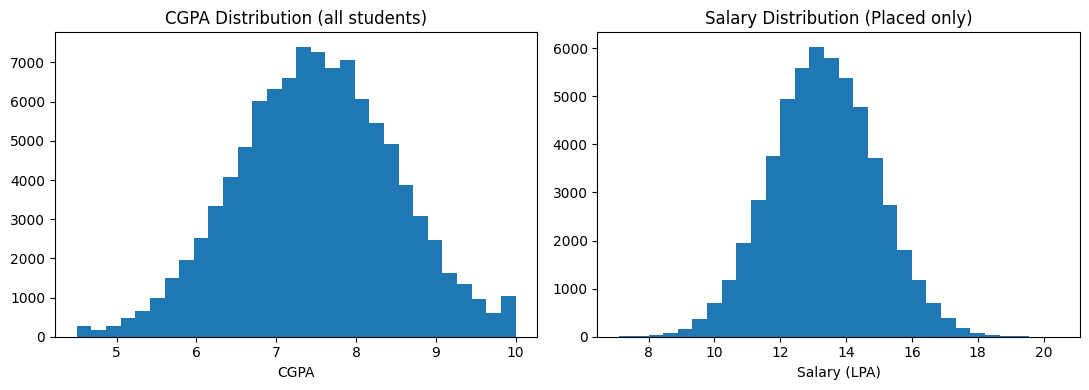

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(raw['cgpa'], bins=30)
axes[0].set_title('CGPA Distribution (all students)')
axes[0].set_xlabel('CGPA')
axes[1].hist(placed['salary_package_lpa'], bins=30)
axes[1].set_title('Salary Distribution (Placed only)')
axes[1].set_xlabel('Salary (LPA)')
plt.tight_layout()
plt.show()

## 4. All numeric features distribution

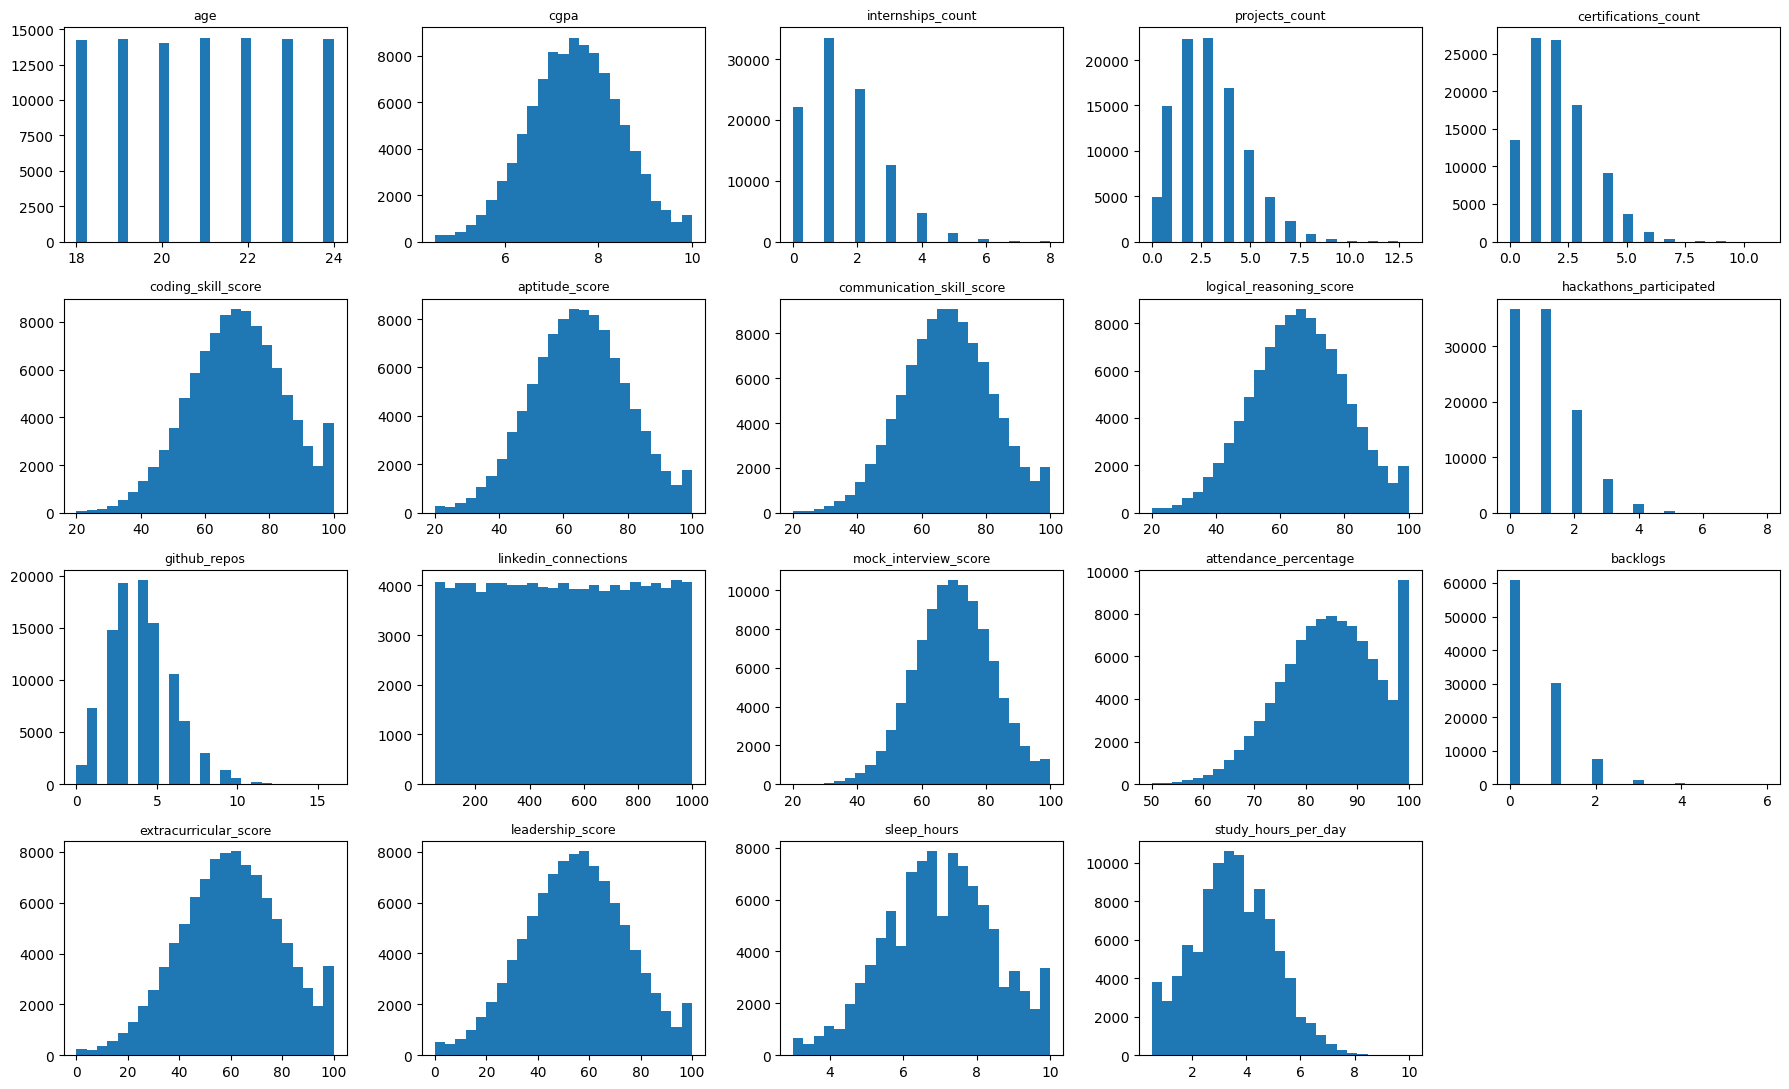

In [12]:
num_cols = [c for c in raw.select_dtypes(include='number').columns if c not in ['student_id', 'salary_package_lpa']]
fig, axes = plt.subplots(4, 5, figsize=(18, 11))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(raw[c], bins=25)
    ax.set_title(c, fontsize=9)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Categorical features vs Placement rate
Har category me kitne % students Placed hue. Agar koi category ka rate alag hota to wo feature placement ke liye useful hota.

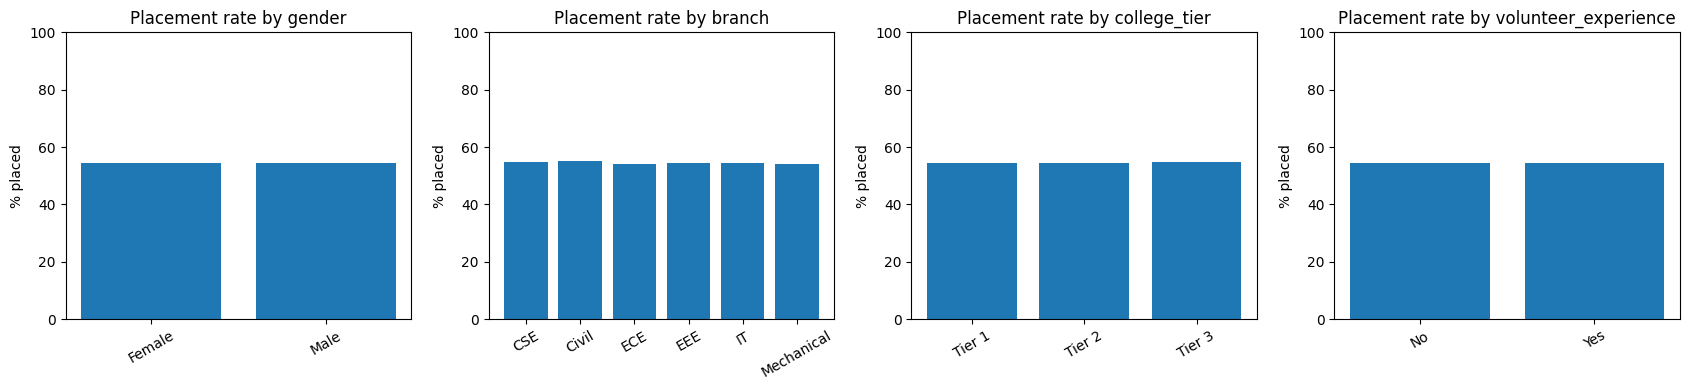

{'Female': 54.38, 'Male': 54.51}
{'CSE': 54.64, 'Civil': 55.17, 'ECE': 54.11, 'EEE': 54.32, 'IT': 54.3, 'Mechanical': 54.08}
{'Tier 1': 54.5, 'Tier 2': 54.28, 'Tier 3': 54.72}
{'No': 54.41, 'Yes': 54.53}


In [13]:
cat_cols = ['gender', 'branch', 'college_tier', 'volunteer_experience']
rates = {c: raw.groupby(c)['placement_status'].apply(lambda s: (s == 'Placed').mean() * 100).round(2) for c in cat_cols}
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes, cat_cols):
    ax.bar(rates[c].index, rates[c].values)
    ax.set_title('Placement rate by ' + c)
    ax.set_ylabel('% placed')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()
for c in cat_cols:
    print(rates[c].to_dict())

## 6. Branch and College Tier behalf Salary

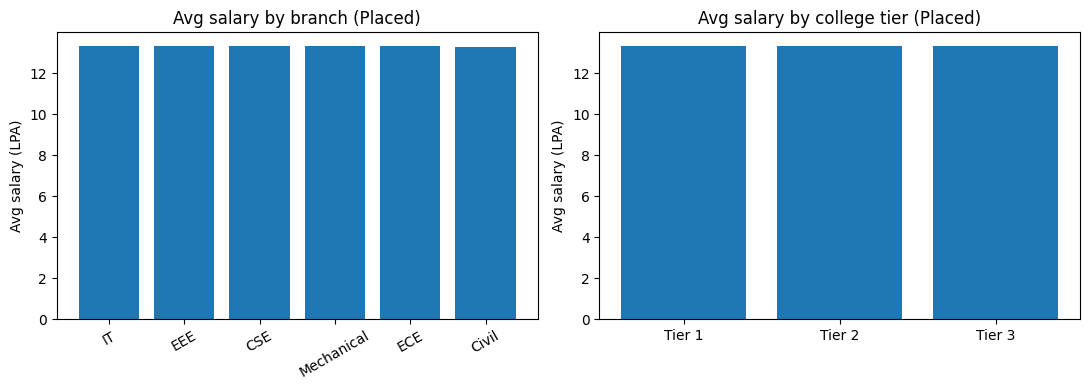

{'IT': 13.332, 'EEE': 13.319, 'CSE': 13.314, 'Mechanical': 13.312, 'ECE': 13.311, 'Civil': 13.305}
{'Tier 1': 13.317, 'Tier 2': 13.315, 'Tier 3': 13.32}


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
b = placed.groupby('branch')['salary_package_lpa'].mean().sort_values(ascending=False)
t = placed.groupby('college_tier')['salary_package_lpa'].mean()
axes[0].bar(b.index, b.values); axes[0].set_title('Avg salary by branch (Placed)'); axes[0].tick_params(axis='x', rotation=30)
axes[1].bar(t.index, t.values); axes[1].set_title('Avg salary by college tier (Placed)')
for ax in axes:
    ax.set_ylabel('Avg salary (LPA)')
plt.tight_layout()
plt.show()
print(b.round(3).to_dict())
print(t.round(3).to_dict())

## 7. Numeric features ka Salary se correlation

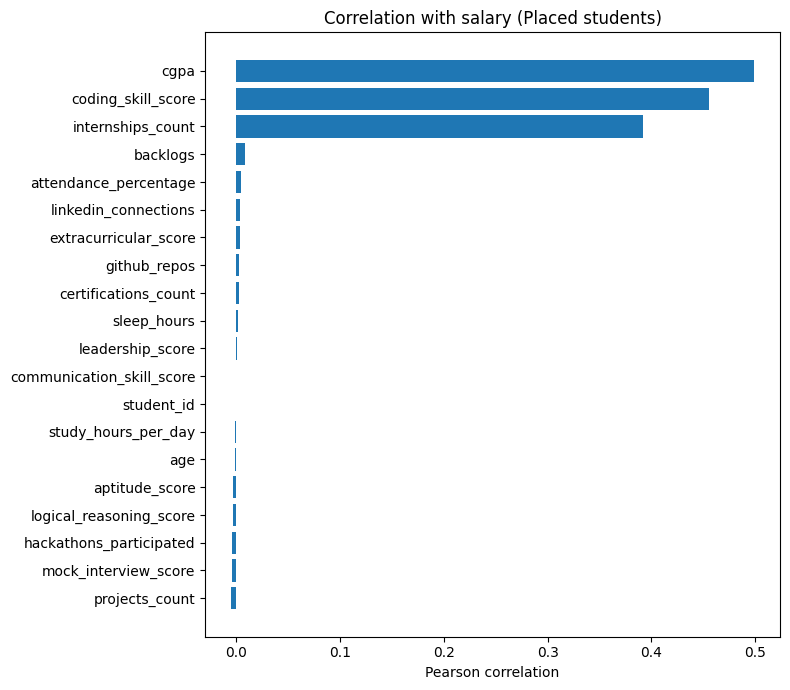

cgpa                     0.499
coding_skill_score       0.455
internships_count        0.392
backlogs                 0.008
attendance_percentage    0.004
linkedin_connections     0.004
Name: salary_package_lpa, dtype: float64

In [15]:
corr = placed.select_dtypes(include='number').corr()['salary_package_lpa'].drop('salary_package_lpa').sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(corr.index, corr.values)
ax.set_title('Correlation with salary (Placed students)')
ax.set_xlabel('Pearson correlation')
plt.tight_layout()
plt.show()
corr.round(3).sort_values(ascending=False).head(6)

## 8. Top features vs Salary (scatter and box plot)

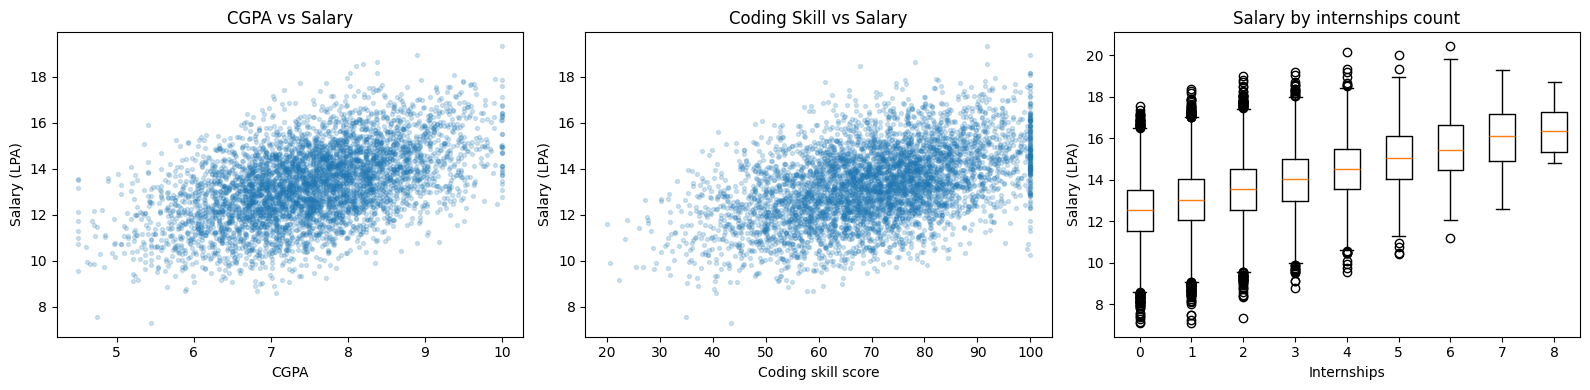

In [16]:
s = placed.sample(5000, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(s['cgpa'], s['salary_package_lpa'], alpha=0.2, s=8); axes[0].set_title('CGPA vs Salary'); axes[0].set_xlabel('CGPA')
axes[1].scatter(s['coding_skill_score'], s['salary_package_lpa'], alpha=0.2, s=8); axes[1].set_title('Coding Skill vs Salary'); axes[1].set_xlabel('Coding skill score')
groups = [g['salary_package_lpa'].values for _, g in placed.groupby('internships_count')]
axes[2].boxplot(groups); axes[2].set_xticklabels(sorted(placed['internships_count'].unique())); axes[2].set_title('Salary by internships count'); axes[2].set_xlabel('Internships')
for ax in axes:
    ax.set_ylabel('Salary (LPA)')
plt.tight_layout()
plt.show()

## 9. Correlation heatmap

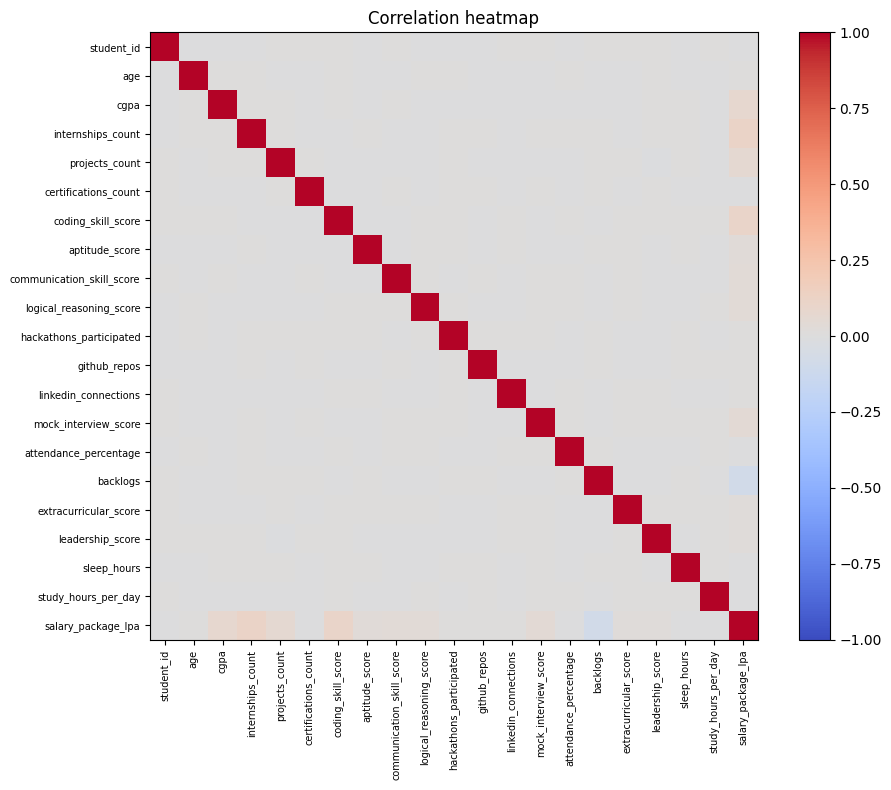

In [17]:
cm = raw.select_dtypes(include='number').corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns, fontsize=7)
plt.colorbar(im)
ax.set_title('Correlation heatmap')
plt.tight_layout()
plt.show()

## 10.which feature decide placement?

In [18]:
diff = raw.groupby('placement_status').mean(numeric_only=True).T
diff['difference_%'] = ((diff['Placed'] - diff['Not Placed']) / diff['Not Placed'] * 100).round(2)
diff.drop('salary_package_lpa').round(3).sort_values('difference_%', key=abs, ascending=False)

placement_status,Not Placed,Placed,difference_%
backlogs,0.561,0.444,-20.88
internships_count,1.417,1.573,11.02
projects_count,2.886,3.098,7.34
coding_skill_score,69.009,70.508,2.17
logical_reasoning_score,65.343,66.424,1.66
leadership_score,54.458,55.339,1.62
mock_interview_score,69.388,70.492,1.59
aptitude_score,64.474,65.418,1.47
communication_skill_score,67.473,68.369,1.33
extracurricular_score,59.464,60.253,1.33


## 11. Outliers check (IQR method)
Har numeric feature me IQR ke bahar kitni values hain. Ye sirf jaanne ke liye hai; outliers hataye nahi gaye (tree models outliers se kam prabhavit hote hain).

In [19]:
rows = []
for c in num_cols + ['salary_package_lpa']:
    q1, q3 = raw[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = int(((raw[c] < q1 - 1.5 * iqr) | (raw[c] > q3 + 1.5 * iqr)).sum())
    rows.append((c, n, round(n / len(raw) * 100, 2)))
pd.DataFrame(rows, columns=['feature', 'outliers', 'percent']).sort_values('outliers', ascending=False).head(8)

,feature,outliers,percent
2,internships_count,6565,6.57
10,github_repos,2163,2.16
14,backlogs,1481,1.48
3,projects_count,1176,1.18
4,certifications_count,438,0.44
12,mock_interview_score,399,0.40
13,attendance_percentage,373,0.37
8,logical_reasoning_score,362,0.36


## 12. EDA ke findings
SEE_RESULTS

---
# Part 3: Data Preprocessing

In [54]:
import os, pickle
import pandas as pd
from sklearn.preprocessing import LabelEncoder

raw = pd.read_csv('../datasets/studentplacement.csv')
df = raw.copy()         
print('Start shape:', df.shape)

Start shape: (100000, 26)


In [21]:
print('Missing before:', int(df.isnull().sum().sum()))
df = df.fillna(df.mean(numeric_only=True))
print('Missing after :', int(df.isnull().sum().sum()))

Missing before: 0
Missing after : 0


In [22]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print('Rows before:', before, '| after:', len(df), '| removed:', before - len(df))

Rows before: 100000 | after: 100000 | removed: 0


## 4. Categorical columns encode (Label Encoding)

In [23]:
encoders = {}
for col in df.select_dtypes(include=['object', 'string']).columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    encoders[col] = le

for col, le in encoders.items():
    print(col, '->', {c: int(i) for i, c in enumerate(le.classes_)})

gender -> {'Female': 0, 'Male': 1}
branch -> {'CSE': 0, 'Civil': 1, 'ECE': 2, 'EEE': 3, 'IT': 4, 'Mechanical': 5}
college_tier -> {'Tier 1': 0, 'Tier 2': 1, 'Tier 3': 2}
volunteer_experience -> {'No': 0, 'Yes': 1}
placement_status -> {'Not Placed': 0, 'Placed': 1}


## 5. Check: ab koi text column bacha?

In [24]:
print('Text columns left:', df.select_dtypes(include=['object', 'string']).columns.tolist())
df.dtypes.value_counts()

Text columns left: []


int64      14
float64    12
Name: count, dtype: int64

## 6. Encoders ko `models/` folder me save 

In [25]:
os.makedirs('../models', exist_ok=True)
with open('../models/encoders.pkl', 'wb') as f:
    pickle.dump(encoders, f)
print('Saved:', os.path.abspath('../models/encoders.pkl'))

Saved: C:\Users\Admin\placement_prediction\models\encoders.pkl


## 7. Processed data `datasets/processed/` save

In [26]:
os.makedirs('../datasets/processed', exist_ok=True)
df.to_csv('../datasets/processed/encoded_data.csv', index=False)
print('Saved encoded_data.csv with shape', df.shape)
df.head()

Saved encoded_data.csv with shape (100000, 26)


,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,1,7.53,4,1,4,6,1,99.238568,81.707722,57.707166,59.070073,4,1,184,72.647009,77.463863,2,63.382726,52.938240,1,6.7,3.6,0,0.00
1,2,21,1,7.92,0,1,1,3,6,80.966123,63.116715,59.197085,78.976419,0,2,539,61.699110,88.887600,1,73.694605,60.198856,0,4.4,2.3,0,0.00
2,3,22,0,8.60,3,0,0,1,1,49.177184,48.658753,92.104885,80.603331,0,2,568,87.396911,74.153265,0,63.329294,43.708803,0,8.8,5.9,1,11.99
3,4,24,1,6.68,0,0,0,2,2,79.359084,66.376653,83.411798,64.187246,1,1,550,58.401069,87.635955,1,47.636099,56.549154,1,8.1,4.4,0,0.00
4,5,20,0,8.43,4,2,1,4,3,65.018573,61.274985,88.956331,56.163678,1,4,833,74.489201,79.120749,1,0.000000,67.268893,0,8.7,3.4,1,12.16


---
# Part 4: Feature Engineering

## 1. Libraries aur encoded data load karna

In [27]:
import json, pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv('../datasets/processed/encoded_data.csv')
encoders = pickle.load(open('../models/encoders.pkl', 'rb'))
TARGET = 'salary_package_lpa'
print(df.shape)

(100000, 26)


## 2. Salary model ke liye sirf Placed students

In [28]:
placed_value = encoders['placement_status'].transform(['Placed'])[0]
salary_df = df[df['placement_status'] == placed_value].copy()
print('Placed code =', placed_value, '| rows for salary model =', len(salary_df))

Placed code = 1 | rows for salary model = 54459


## 3. which features are candidate?

In [29]:
candidates = [c for c in salary_df.columns if c not in ['student_id', 'placement_status', TARGET]]
print(len(candidates), 'candidate features')
candidates

23 candidate features


['age',
 'gender',
 'cgpa',
 'branch',
 'college_tier',
 'internships_count',
 'projects_count',
 'certifications_count',
 'coding_skill_score',
 'aptitude_score',
 'communication_skill_score',
 'logical_reasoning_score',
 'hackathons_participated',
 'github_repos',
 'linkedin_connections',
 'mock_interview_score',
 'attendance_percentage',
 'backlogs',
 'extracurricular_score',
 'leadership_score',
 'volunteer_experience',
 'sleep_hours',
 'study_hours_per_day']

## 4. Feature importance find

In [30]:
fs = salary_df.sample(20000, random_state=42)
rf_fs = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_fs.fit(fs[candidates], fs[TARGET])
imp = pd.DataFrame({
    'feature': candidates,
    'rf_importance': rf_fs.feature_importances_,
    'correlation_with_salary': salary_df[candidates].corrwith(salary_df[TARGET]).values
}).sort_values('rf_importance', ascending=False).reset_index(drop=True)
imp.round(4)

,feature,rf_importance,correlation_with_salary
0,cgpa,0.3389,0.4987
1,coding_skill_score,0.2761,0.4554
2,internships_count,0.1912,0.3916
3,leadership_score,0.0177,0.0007
4,aptitude_score,0.0164,-0.0030
5,logical_reasoning_score,0.0161,-0.0032
6,extracurricular_score,0.0158,0.0033
7,attendance_percentage,0.0157,0.0041
8,mock_interview_score,0.0155,-0.0040
9,linkedin_connections,0.0152,0.0038


## 5. Importance chart

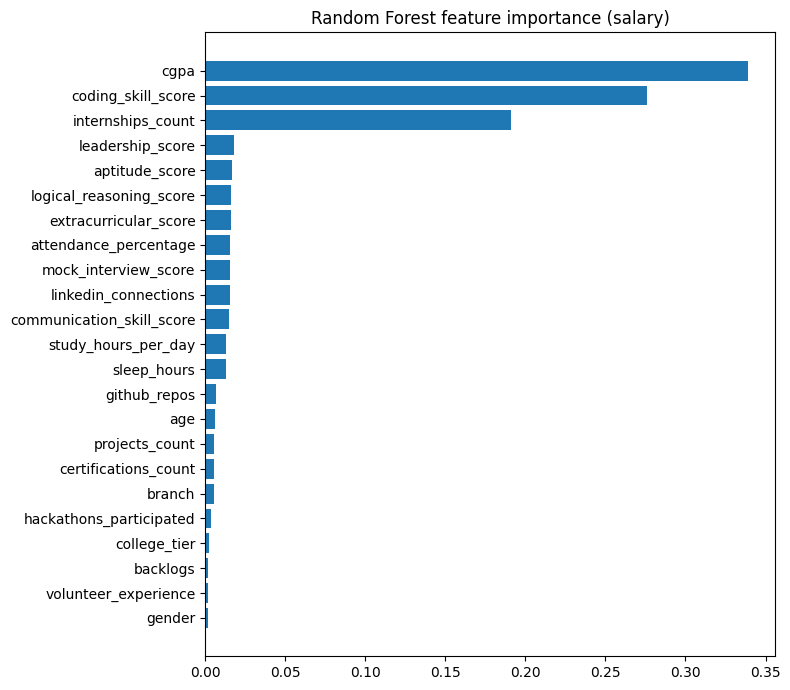

In [31]:
top = imp.sort_values('rf_importance')
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top['feature'], top['rf_importance'])
ax.set_title('Random Forest feature importance (salary)')
plt.tight_layout()
plt.show()

## 6. Final features selection

In [32]:
SELECTED_FEATURES = [
    'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count',
    'certifications_count', 'coding_skill_score', 'aptitude_score',
    'communication_skill_score', 'mock_interview_score',
    'attendance_percentage', 'backlogs'
]
imp['selected'] = imp['feature'].isin(SELECTED_FEATURES)
print('Selected:', len(SELECTED_FEATURES))
print('Selected features ki importance ka total:', round(imp.loc[imp['selected'], 'rf_importance'].sum(), 4))
imp[['feature', 'rf_importance', 'selected']].round(4)

Selected: 12
Selected features ki importance ka total: 0.8894


,feature,rf_importance,selected
0,cgpa,0.3389,True
1,coding_skill_score,0.2761,True
2,internships_count,0.1912,True
3,leadership_score,0.0177,False
4,aptitude_score,0.0164,True
5,logical_reasoning_score,0.0161,False
6,extracurricular_score,0.0158,False
7,attendance_percentage,0.0157,True
8,mock_interview_score,0.0155,True
9,linkedin_connections,0.0152,False


## 7. Train/Test split
80% training, 20% testing

In [33]:
X = salary_df[SELECTED_FEATURES].copy()
y = salary_df[TARGET].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (43567, 12) | Test: (10892, 12)


## 8. Splits and feature list save

In [34]:
X_train.to_csv('../datasets/processed/X_train.csv', index=False)
X_test.to_csv('../datasets/processed/X_test.csv', index=False)
y_train.to_csv('../datasets/processed/y_train.csv', index=False)
y_test.to_csv('../datasets/processed/y_test.csv', index=False)
json.dump(SELECTED_FEATURES, open('../models/feature_columns.json', 'w'), indent=2)
print('Saved X_train, X_test, y_train, y_test and feature_columns.json')

Saved X_train, X_test, y_train, y_test and feature_columns.json


---
# Part 5: Model Training

In [35]:
import os, time, pickle
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor

X_train = pd.read_csv('../datasets/processed/X_train.csv')
y_train = pd.read_csv('../datasets/processed/y_train.csv').squeeze()
print(X_train.shape, y_train.shape)

(43567, 12) (43567,)


In [36]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=15, min_samples_split=10, min_samples_leaf=3, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=500, max_depth=25, min_samples_split=4, min_samples_leaf=2, max_features=0.8, bootstrap=True, random_state=42, n_jobs=-1),
    'Extra Trees': ExtraTreesRegressor(n_estimators=400, max_depth=None, min_samples_split=3, min_samples_leaf=1, max_features=0.9, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, min_samples_split=5, min_samples_leaf=2, loss='huber', random_state=42),
}
list(models)

['Linear Regression',
 'Decision Tree',
 'Random Forest',
 'Extra Trees',
 'Gradient Boosting']

## 3. Models training 

In [37]:
times = {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    times[name] = round(time.time() - t0, 1)
    print(f'{name:20s} trained in {times[name]} s')

Linear Regression    trained in 0.1 s
Decision Tree        trained in 0.8 s
Random Forest        trained in 66.8 s
Extra Trees          trained in 30.9 s
Gradient Boosting    trained in 70.8 s


## 4. Models `.pkl` save 

In [38]:
os.makedirs('../models', exist_ok=True)
files = {
    'Linear Regression': 'linear_regression.pkl',
    'Decision Tree': 'decision_tree.pkl',
    'Random Forest': 'random_forest.pkl',
    'Extra Trees': 'extra_trees.pkl',
    'Gradient Boosting': 'gradient_boosting.pkl',
}
for name, fname in files.items():
    with open(os.path.join('../models', fname), 'wb') as f:
        pickle.dump(models[name], f)
print('Saved all models in ../models')

Saved all models in ../models


## 5. Saved files size check

In [39]:
pd.DataFrame([
    {'file': f, 'size_MB': round(os.path.getsize(os.path.join('../models', f)) / 1e6, 1)}
    for f in sorted(os.listdir('../models')) if f.endswith('.pkl') or f.endswith('.json')
])

,file,size_MB
0,decision_tree.pkl,0.7
1,encoders.pkl,0.0
2,extra_trees.pkl,1677.6
3,feature_columns.json,0.0
4,gradient_boosting.pkl,0.7
5,linear_regression.pkl,0.0
6,random_forest.pkl,852.7


---
# Part 6: Model Evaluation

## 0. Memory free 

In [40]:
import gc
models = None
gc.collect()

39

In [41]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_test = pd.read_csv('../datasets/processed/X_test.csv')
y_test = pd.read_csv('../datasets/processed/y_test.csv').squeeze()
files = {'Linear Regression': 'linear_regression.pkl', 'Decision Tree': 'decision_tree.pkl', 'Random Forest': 'random_forest.pkl', 'Extra Trees': 'extra_trees.pkl', 'Gradient Boosting': 'gradient_boosting.pkl'}
models = {n: pickle.load(open('../models/' + f, 'rb')) for n, f in files.items()}
print('Loaded:', list(models))

Loaded: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'Gradient Boosting']


## 2. Test set behalf predictions

In [42]:
preds = {n: m.predict(X_test) for n, m in models.items()}
print({n: p[:3].round(2).tolist() for n, p in preds.items()})

{'Linear Regression': [12.53, 13.55, 10.66], 'Decision Tree': [14.08, 13.85, 11.88], 'Random Forest': [12.77, 13.7, 10.82], 'Extra Trees': [12.72, 14.02, 10.5], 'Gradient Boosting': [12.5, 13.41, 10.86]}


## 3. Metrics 

In [43]:
rows = []
for n, p in preds.items():
    mse = mean_squared_error(y_test, p)
    rows.append({'Model': n, 'MAE': mean_absolute_error(y_test, p), 'MSE': mse, 'RMSE': np.sqrt(mse), 'R2 Score': r2_score(y_test, p)})
metrics_df = pd.DataFrame(rows).sort_values('R2 Score', ascending=False).reset_index(drop=True)
metrics_df.to_csv('../models/model_metrics.csv', index=False)
metrics_df.round(4)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.7983,0.9978,0.9989,0.6061
1,Gradient Boosting,0.8014,1.0056,1.0028,0.6030
2,Random Forest,0.8198,1.0489,1.0242,0.5859
3,Extra Trees,0.8268,1.0672,1.0330,0.5787
4,Decision Tree,0.9804,1.5103,1.2290,0.4038


## 4. Metrics ka chart

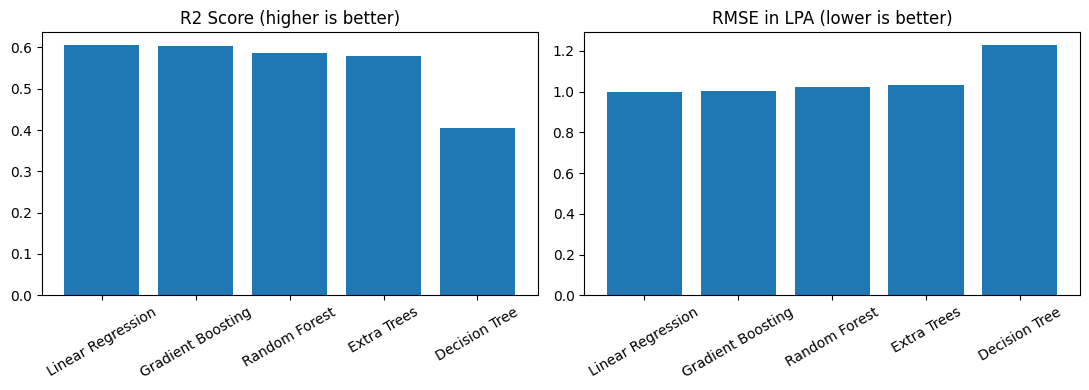

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(metrics_df['Model'], metrics_df['R2 Score']); axes[0].set_title('R2 Score (higher is better)')
axes[1].bar(metrics_df['Model'], metrics_df['RMSE']); axes[1].set_title('RMSE in LPA (lower is better)')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## 5. Best model  Actual vs Predicted and Residuals

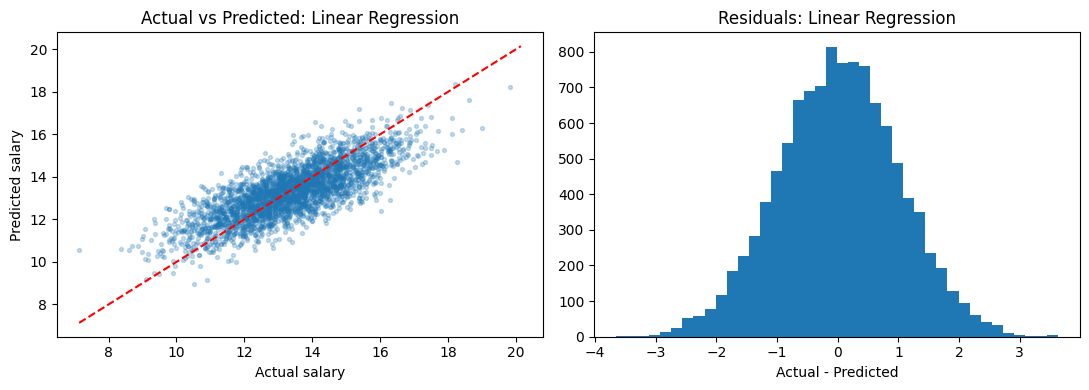

Best model: Linear Regression


In [45]:
best = metrics_df.loc[0, 'Model']
p = preds[best]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
idx = np.random.RandomState(0).choice(len(y_test), 3000, replace=False)
axes[0].scatter(y_test.values[idx], p[idx], alpha=0.25, s=8)
lo, hi = y_test.min(), y_test.max()
axes[0].plot([lo, hi], [lo, hi], 'r--')
axes[0].set_xlabel('Actual salary'); axes[0].set_ylabel('Predicted salary'); axes[0].set_title('Actual vs Predicted: ' + best)
axes[1].hist(y_test.values - p, bins=40)
axes[1].set_title('Residuals: ' + best); axes[1].set_xlabel('Actual - Predicted')
plt.tight_layout()
plt.show()
print('Best model:', best)

## 6. Random Forest feature importance

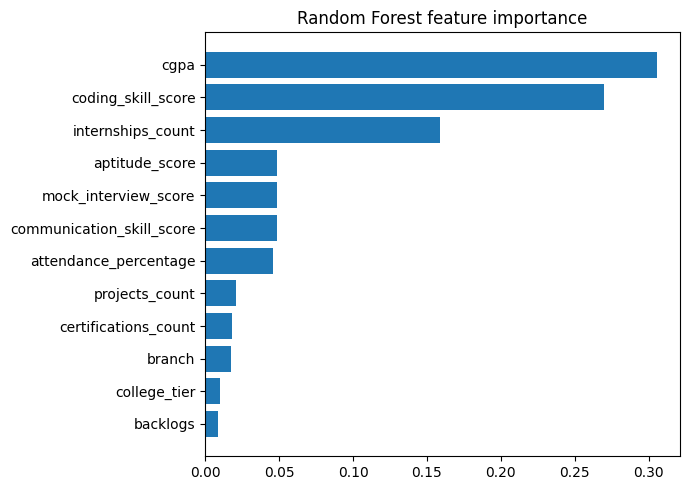

cgpa                    0.3059
coding_skill_score      0.2694
internships_count       0.1585
aptitude_score          0.0487
mock_interview_score    0.0486
dtype: float64

In [46]:
rf = models['Random Forest']
fi = pd.Series(rf.feature_importances_, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(fi.index, fi.values)
ax.set_title('Random Forest feature importance')
plt.tight_layout()
plt.show()
fi.sort_values(ascending=False).round(4).head(5)

## 7. Dashboard numbers vs notebook real numbers

In [47]:
dashboard_r2 = {'Linear Regression': 0.9797, 'Decision Tree': 0.9745, 'Random Forest': 0.9872}
cmp = pd.DataFrame({'Dashboard page (hard-coded) R2': dashboard_r2})
cmp['This notebook R2'] = metrics_df.set_index('Model')['R2 Score'].reindex(cmp.index).round(4)
cmp

,Dashboard page (hard-coded) R2,This notebook R2
Linear Regression,0.9797,0.6061
Decision Tree,0.9745,0.4038
Random Forest,0.9872,0.5859


---
# Part 7: Streamlit Dashboard run

In [51]:
import os, sys, time, subprocess

PROJECT_ROOT = os.path.abspath('..')      # notebook/ se ek folder upar
PORT = 8501

dash = subprocess.Popen(
    [sys.executable, '-m', 'streamlit', 'run', 'dashboard/app/streamlit/main.py',
     '--server.port', str(PORT), '--server.headless', 'true',
     '--browser.gatherUsageStats', 'false'],
    cwd=PROJECT_ROOT
)
time.sleep(6)
print(f'Dashboard chal raha hai. Browser me kholo: http://localhost:{PORT}')

Dashboard chal raha hai. Browser me kholo: http://localhost:8501


##  Dashboard close

In [50]:
dash.terminate()
print('Dashboard band ho gaya.')

Dashboard band ho gaya.
